## 01 - EDA Exploratory Data Analysis - data splits

In this notebook, we are going to:
- extract text from transcribed txt files
- map the text to its corresponding labels (AD/CN)
- do EDA (Exploratory Data Analysis) on the train set 

We will then split the train set into 2 sets: train and development, with the ratio 50/50

In [72]:
# import required packages
import pandas as pd
import os
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [73]:
# labels
# AD = Alzheimer's Disease (positive class)
# CN = Cognitively Normal (negative class)

In [74]:
# please point to correct downloaded transcribed folders of the original dataset
data_path = "../../../data/" 
path_ad = data_path + "Transcribed Data-2024-Feb-13/Diagnosis Training Data/ad transcribed/"
path_cn = data_path + "Transcribed Data-2024-Feb-13//Diagnosis Training Data/cn transcribed/"
mmse_scores_fname = data_path + "Training Dataset/Diagnosis training data/ADReSSo21/diagnosis/train/adresso-train-mmse-scores.csv"

In [75]:
# read MMSE data
mmse_df = pd.read_csv(mmse_scores_fname, usecols=["adressfname", "mmse", "dx"])
mmse_df

,adressfname,mmse,dx
0,adrso024,20,ad
1,adrso025,11,ad
2,adrso027,18,ad
3,adrso028,18,ad
4,adrso031,26,ad
...,...,...,...
161,adrso309,30,cn
162,adrso310,28,cn
163,adrso312,29,cn
164,adrso315,28,cn


In [76]:
train_data = {"ad":[], 
              "cn":[]
             }

file_names = {"ad":[],
              "cn":[]
             }

In [77]:
def read_data(path):
    """
        get data from "txt" files from a specified folder (ad/cn)
        returns list of text (strings)
    """
    result = []
    filenames = []
    # get only txt files and sort them to ensure compatibility across different systems
    files = sorted([item
             for item in os.listdir(path)
             if item.endswith("txt")
            ])
    
    for fname in files:
        print("Processing files =", fname) #, end="\r")
        with open(path + fname, encoding="utf-8") as f:
            lines = f.readlines()
            print("Line len =", len(lines)) #, end="\r")
            text = "\n".join(lines)
            result.append(text)
            filenames.append(fname.replace(".txt", "")) # remove txt extensions

    return (result, filenames)

train_data["ad"], file_names["ad"] = read_data(path_ad)
train_data["cn"], file_names["cn"] = read_data(path_cn)

Processing files = adrso024.txt
Line len = 23
Processing files = adrso025.txt
Line len = 13
Processing files = adrso027.txt
Line len = 9
Processing files = adrso028.txt
Line len = 17
Processing files = adrso031.txt
Line len = 29
Processing files = adrso032.txt
Line len = 5
Processing files = adrso033.txt
Line len = 7
Processing files = adrso035.txt
Line len = 9
Processing files = adrso036.txt
Line len = 21
Processing files = adrso039.txt
Line len = 9
Processing files = adrso043.txt
Line len = 27
Processing files = adrso045.txt
Line len = 35
Processing files = adrso046.txt
Line len = 13
Processing files = adrso047.txt
Line len = 3
Processing files = adrso049.txt
Line len = 15
Processing files = adrso053.txt
Line len = 21
Processing files = adrso054.txt
Line len = 21
Processing files = adrso055.txt
Line len = 9
Processing files = adrso056.txt
Line len = 29
Processing files = adrso059.txt
Line len = 3
Processing files = adrso060.txt
Line len = 19
Processing files = adrso063.txt
Line len =

In [78]:
# double check data
assert len(train_data["ad"]) == 87
assert len(train_data["cn"]) == 79
assert train_data["ad"][0].startswith("The cookie jar and the little")
assert train_data["ad"][1].startswith("Tell me everything that's going on")
assert train_data["cn"][0].startswith("Okay, I see a mom doing")
assert train_data["cn"][1].startswith("Starting from the left I see")
print("Passed")

Passed


In [79]:
# assert filenames
assert file_names["ad"][0].startswith("adrso024")
assert file_names["ad"][1].startswith("adrso025")
assert file_names["ad"][-1].startswith("adrso253")

assert file_names["cn"][0].startswith("adrso002")
assert file_names["cn"][1].startswith("adrso003")
assert file_names["cn"][-1].startswith("adrso316")

print("Passed")

Passed


In [80]:
# take a look at the data
print(train_data["ad"][0][:100])

The cookie jar and the little



boy about down on the floor



girls



Girls anyway the housewife



In [81]:
# take a look at the data
print(train_data["cn"][0][:100])

Okay, I see a mom doing the dishes and the waters overflowing from the sink and she seems to be comp


In [82]:
print(file_names["ad"][0:5])

['adrso024', 'adrso025', 'adrso027', 'adrso028', 'adrso031']


In [83]:
print(file_names["cn"][0:5])

['adrso002', 'adrso003', 'adrso005', 'adrso007', 'adrso008']


In [84]:
# build word-clouds
def make_wordcloud(text_list):
    """
    display a wordcloud based on the text list
    parameters:
        text_list: list of text (paragraphs)
    returns:
        list of frequent words        
    """
    text = "\n".join(text_list).lower()
    wordcloud = WordCloud().generate(text)

    # process text and return counts of frequent words
    result = sorted(WordCloud().process_text(text).items(), 
                    key=lambda item: item[1],
                    reverse=True
                   )
    
    
    plt.imshow(wordcloud)
    plt.axis("off")
    plt.show()

    return result

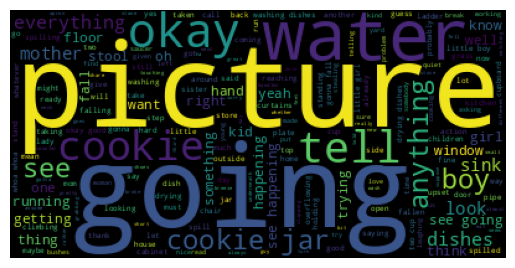

[('picture', 102), ('going', 100), ('water', 98), ('okay', 80), ('tell', 69), ('cookie', 63), ('cookie jar', 59), ('see', 58), ('boy', 57), ('anything', 56), ('everything', 52), ('dishes', 52), ('mother', 46), ('sink', 45), ('look', 44), ('see going', 42), ('girl', 41), ('oh', 41), ('one', 38), ('floor', 36), ('well', 36), ('running', 33), ('happening', 32), ('kid', 30), ('hand', 28), ('right', 27), ('know', 26), ('getting', 25), ('yeah', 24), ('want', 24), ('stool', 24), ('thing', 23), ('see happening', 23), ('trying', 22), ('fall', 22), ('something', 21), ('window', 21), ('think', 21), ('washing dishes', 21), ('falling', 20), ('say', 18), ('now', 18), ('plate', 17), ('action', 17), ('little girl', 17), ('okay good', 17), ('still', 16), ('go', 15), ('washing', 15), ('chair', 15)]


In [85]:
# see the most frequent words of AD (positive) group
ad_top_words = make_wordcloud(train_data["ad"])
print(ad_top_words[:50])
ad_top_words_set = set([w
                        for w, count in ad_top_words[:200]
                       ])

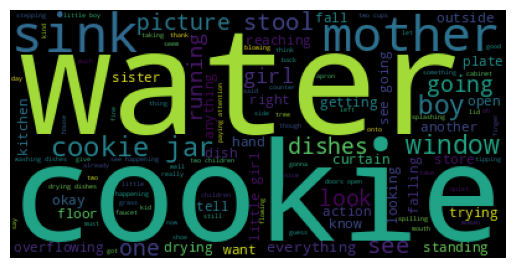

[('water', 102), ('cookie', 97), ('sink', 85), ('mother', 75), ('cookie jar', 75), ('boy', 71), ('window', 69), ('stool', 54), ('see', 53), ('picture', 53), ('going', 53), ('one', 52), ('look', 52), ('dishes', 51), ('girl', 46), ('running', 46), ('everything', 45), ('okay', 41), ('reaching', 40), ('getting', 38), ('tell', 38), ('floor', 37), ('hand', 35), ('drying', 34), ('overflowing', 33), ('right', 32), ('curtain', 31), ('standing', 30), ('open', 29), ('falling', 28), ('fall', 26), ('sister', 26), ('want', 24), ('little girl', 24), ('action', 23), ('plate', 22), ('anything', 21), ('see going', 21), ('know', 20), ('looking', 20), ('kitchen', 20), ('trying', 20), ('outside', 19), ('dish', 19), ('another', 19), ('store', 19), ('washing dishes', 18), ('onto', 17), ('thing', 17), ('little boy', 17)]


In [86]:
# see the most frequent words of CN (negative) group
cn_top_words = make_wordcloud(train_data["cn"])
print(cn_top_words[:50])
cn_top_words_set = set([w
                        for w, count in cn_top_words[:200]
                       ])

In [87]:
# observe the difference in 2 word set
ad_unique = ad_top_words_set - cn_top_words_set
cn_unique = cn_top_words_set - ad_top_words_set
print("AD unique words =\n", ad_unique)
print("----------------")
print("CN unique words =\n", cn_unique)


AD unique words =
 {'ha', 'cup', 'almost', 'whatever', 'young', 'touching', 'whoa whoa', 'somebody', 'stove', 'yes', 'bushes', 'grabbing', 'sorry', 'break', 'try', 'fell', 'taken', 'underneath', 'suppose', 'rather', 'lady', 'new', 'neck', 'watching', 'call', 'ladder', 'upset', 'given', 'problem', 'saucer', 'find', 'pretty', 'stone', 'spill', 'hard', 'eat', 'told', 'wash', 'love', 'read', 'third', 'step', 'assume', 'shoes', 'lot', 'curtains', 'made', 'handles', 'spilled', 'guy', 'share', 'two cup', 'always', 'whether', 'gotta', 'goes', 'small', 'us', 'working', 'home', 'next', 'broke', 'telling', 'cooking', 'stealing', 'slipping', 'okay good', 'stand', 'put', 'different', 'breeze', 'pipe'}
----------------
CN unique words =
 {'either', 'dress', 'blowing', 'path', 'walking', 'wiping', 'doors open', 'oblivious', 'corner', 'come', 'shelf', 'giving', 'ground', 'show', 'shoe', 'stealing cookies', 'wrong', 'paying', 'finger', 'crash', 'grab', 'stepping', 'lid', 'wet', 'place', 'curtain', 'dri

### Observations
We can see that there are some words that are common in both categories (AD/CN):
- cookie, cookie jar, water, sink, boy, girl, etc

Some words that frequently appear in AD (positive) group, but not so frequently in CN (negative) groups:
- almost, okay good, suppose, somebody, broke, etc

These words tend to be generic (not with very specific meaning)

Some words that frequently appear in CN (negative) group, but not so frequently in AD (positive) groups:
- stepping, dress, splashing, grab, accident, etc

These words tend to be more specific and detailed. 

In [88]:
# combine data into a dataframe, for export to a csv for further processing
train_dict = {
    "file_id": [],  #  file name
    "text": [],    # the transcript
    "target": []   # the target: positive (AD), negative (CN)
}
for item, fname in zip(train_data["ad"], file_names["ad"]):
    train_dict["file_id"].append(fname)
    train_dict["text"].append(item)
    train_dict["target"].append("AD")

for item, fname in zip(train_data["cn"], file_names["cn"]):
    train_dict["file_id"].append(fname)
    train_dict["text"].append(item)
    train_dict["target"].append("CN")

print("Text count =", len(train_dict["text"]))
print("Target count =", len(train_dict["target"]))
print("File_id count =", len(train_dict["target"]))

Text count = 166
Target count = 166
File_id count = 166


In [89]:
train_df = pd.DataFrame(train_dict)
train_df = train_df.merge(mmse_df, left_on="file_id", right_on="adressfname")[
    ["file_id", "text", "target", "mmse"]
]
print(len(train_df))
train_df.head()

166


,file_id,text,target,mmse
0,adrso024,The cookie jar and the little\n\n\n\nboy about...,AD,20
1,adrso025,Tell me everything that's going on\n\n\n\nthe ...,AD,11
2,adrso027,As a picture little girl and a little boy stan...,AD,18
3,adrso028,She will find her mother worship trying to dis...,AD,18
4,adrso031,What do you see going on\n\n\n\nthe boys on a ...,AD,26


In [90]:
train_df.describe(include="all")

,file_id,text,target,mmse
count,166,166,166,166.000000
unique,166,166,2,NaN
top,adrso024,The cookie jar and the little\n\n\n\nboy about...,AD,NaN
freq,1,1,87,NaN
mean,NaN,NaN,NaN,22.933735
std,NaN,NaN,NaN,6.992754
min,NaN,NaN,NaN,3.000000
25%,NaN,NaN,NaN,17.250000
50%,NaN,NaN,NaN,26.000000
75%,NaN,NaN,NaN,29.000000


We can see we have total of 166 examples, with 87 positive (AD) and 79 negative (CN). The train_set is relatively balanced. 

In [91]:
train_df.groupby("target")[["mmse"]].agg(["count", "min", "mean", "median", "max"])

mmse                          
       count min       mean median max
target                                
AD        87   3  17.436782   18.0  28
CN        79  26  28.987342   29.0  30

We also see that the MMSE, which evaluates the presence and severity of cognitive impairment, is drastically higher for the CN group than the AD group for both the median and mean, which is to be expected.

Now we can split the data into train and dev set

In [99]:
train_set_df = train_df.sample(frac=0.5, random_state=42)
print(train_set_df.describe(include="all"))
train_set_df.head()

         file_id                                               text target  \
count         83                                                 83     83   
unique        83                                                 83      2   
top     adrso021  Everything you see going on in this picture, g...     AD   
freq           1                                                  1     47   
mean         NaN                                                NaN    NaN   
std          NaN                                                NaN    NaN   
min          NaN                                                NaN    NaN   
25%          NaN                                                NaN    NaN   
50%          NaN                                                NaN    NaN   
75%          NaN                                                NaN    NaN   
max          NaN                                                NaN    NaN   

             mmse  
count   83.000000  
unique        NaN  
top

,file_id,text,target,mmse
100,adrso021,"Everything you see going on in this picture, g...",CN,28
136,adrso265,"Now you just look at the picture. Okay, this i...",CN,30
78,adrso237,Tell me everything that you see going on in th...,AD,20
56,adrso197,Girls and boys getting her one that stores sto...,AD,20
97,adrso017,"All right, we have a few more tasks to go thro...",CN,30


In [100]:
dev_set_df = train_df.drop(train_set_df.index)
print(dev_set_df.describe(include="all"))
dev_set_df.head()

         file_id                                               text target  \
count         83                                                 83     83   
unique        83                                                 83      2   
top     adrso025  Tell me everything that's going on\n\n\n\nthe ...     CN   
freq           1                                                  1     43   
mean         NaN                                                NaN    NaN   
std          NaN                                                NaN    NaN   
min          NaN                                                NaN    NaN   
25%          NaN                                                NaN    NaN   
50%          NaN                                                NaN    NaN   
75%          NaN                                                NaN    NaN   
max          NaN                                                NaN    NaN   

             mmse  
count   83.000000  
unique        NaN  
top

,file_id,text,target,mmse
1,adrso025,Tell me everything that's going on\n\n\n\nthe ...,AD,11
3,adrso028,She will find her mother worship trying to dis...,AD,18
5,adrso032,What's going on well the children are climbing...,AD,25
7,adrso035,Okay here's the picture tell me I'll tell you ...,AD,24
8,adrso036,Tell me what's going on\n\n\n\nall the action ...,AD,10


In [94]:
# make sure there's no overlap between train and dev set
for filename in train_set_df["file_id"]:
    if filename in dev_set_df["file_id"]:
        print("Duplicate detected")
    assert filename not in dev_set_df["file_id"]

print("Passed")

Passed


In [95]:
# write to csv
path = data_path + "splits/"

In [96]:
train_set_df.head()

,file_id,text,target,mmse
100,adrso021,"Everything you see going on in this picture, g...",CN,28
136,adrso265,"Now you just look at the picture. Okay, this i...",CN,30
78,adrso237,Tell me everything that you see going on in th...,AD,20
56,adrso197,Girls and boys getting her one that stores sto...,AD,20
97,adrso017,"All right, we have a few more tasks to go thro...",CN,30


In [97]:
dev_set_df.head()

,file_id,text,target,mmse
1,adrso025,Tell me everything that's going on\n\n\n\nthe ...,AD,11
3,adrso028,She will find her mother worship trying to dis...,AD,18
5,adrso032,What's going on well the children are climbing...,AD,25
7,adrso035,Okay here's the picture tell me I'll tell you ...,AD,24
8,adrso036,Tell me what's going on\n\n\n\nall the action ...,AD,10


In [98]:
print("Writing to csv files...")

train_set_df.to_csv(path + "train_50pc.csv",
                   index=False)
dev_set_df.to_csv(path + "dev_50pc.csv",
                 index=False)
print("Completed")

Writing to csv files...
Completed
